#### Workflow for Anomaly Detection: ####

- Train the model on the training data to estimate the parameters (mean and covariance for multivariate, mean and standard deviation for univariate).
- Tune the threshold (epsilon) using the training data (e.g., by selecting a value that flags a reasonable number of anomalies or using cross-validation).
- Apply the model and the chosen epsilon to the test data to detect anomalies.


#### How to Tune epsilon: ####

1. Visual Inspection: Plot the probabilities and choose epsilon such that it captures the tail of the distribution.
2. Quantile-Based: Set epsilon to a low quantile (e.g., 1st or 5th percentile) of the training probabilities.
3. Domain Knowledge: Use prior knowledge to set a reasonable threshold.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, norm

from sklearn.preprocessing import StandardScaler

In [20]:

# Load the data
ano_train = pd.read_csv('ano_train.csv', header=None).values
ano_test = pd.read_csv('ano_test.csv', header=None).values

# Normalize the data
scaler = StandardScaler()
ano_train_scaled = scaler.fit_transform(ano_train)
ano_test_scaled = scaler.transform(ano_test)


In [21]:
# Anomaly detection functions
def univariate_gaussian_anomaly_detection(data, mu, sigma, epsilon=0.01):
    p = np.prod(norm.pdf(data, loc=mu, scale=sigma), axis=1)
    anomalies = p < epsilon
    return anomalies, p

def multivariate_gaussian_anomaly_detection_singular(data, mu, cov, epsilon=0.01):
    mv_normal = multivariate_normal(mean=mu, cov=cov, allow_singular=True)
    p = mv_normal.pdf(data)
    anomalies = p < epsilon
    return anomalies, p

In [22]:
# Plotting function
def plot_contours_with_data(data, anomalies, mu, cov=None, title="Anomaly Detection"):
    plt.figure(figsize=(6, 5))  # Smaller figure size
    plt.scatter(data[:, 0], data[:, 1], c=anomalies, cmap='coolwarm', alpha=0.7, s=20, edgecolors='none')
    plt.title(title, fontsize=10)
    plt.xlabel("Feature 1", fontsize=9)
    plt.ylabel("Feature 2", fontsize=9)

    # Set axis limits to zoom in on the data
    plt.xlim(data[:, 0].min() - 0.5, data[:, 0].max() + 0.5)
    plt.ylim(data[:, 1].min() - 5, data[:, 1].max() + 5)

    x, y = np.meshgrid(
        np.linspace(data[:, 0].min(), data[:, 0].max(), 100),
        np.linspace(data[:, 1].min(), data[:, 1].max(), 100)
    )
    grid = np.stack([x.ravel(), y.ravel()], axis=1)

    if cov is not None:  # Multivariate
        mv_normal = multivariate_normal(mean=mu, cov=cov, allow_singular=True)
        z = mv_normal.pdf(grid).reshape(x.shape)
    else:  # Univariate
        z = np.prod(norm.pdf(grid, loc=mu, scale=np.std(data, axis=0)), axis=1).reshape(x.shape)

    # Plot contour with lower alpha for better visibility of data points
    plt.contour(x, y, z, levels=10, colors='k', alpha=0.3, linewidths=0.5)
    plt.colorbar(label="Anomaly (Red) / Normal (Blue)", shrink=0.8)
    plt.tight_layout()  # Remove unnecessary whitespace
    plt.show()




In [23]:
# Fit models on scaled training data
mu_u_train = np.mean(ano_train_scaled, axis=0)
sigma_u_train = np.std(ano_train_scaled, axis=0)
mu_m_train = np.mean(ano_train_scaled, axis=0)
cov_m_train = np.cov(ano_train_scaled.T)
cov_m_train += 1e-6 * np.eye(cov_m_train.shape[0])  # Regularization

# Manually set epsilon values
epsilon_u = 0.01  # Change this value as needed
epsilon_m = 0.01  # Change this value as needed

# Apply models to scaled training data
univariate_anomalies_train, p_u_train = univariate_gaussian_anomaly_detection(ano_train_scaled, mu_u_train, sigma_u_train, epsilon_u)
multivariate_anomalies_train, p_m_train = multivariate_gaussian_anomaly_detection_singular(ano_train_scaled, mu_m_train, cov_m_train, epsilon_m)

# Apply models to scaled test data
univariate_anomalies_test, _ = univariate_gaussian_anomaly_detection(ano_test_scaled, mu_u_train, sigma_u_train, epsilon_u)
multivariate_anomalies_test, _ = multivariate_gaussian_anomaly_detection_singular(ano_test_scaled, mu_m_train, cov_m_train, epsilon_m)

# Extract the actual anomaly points
anomalous_points_univariate_train = ano_train_scaled[univariate_anomalies_train]
anomalous_points_multivariate_train = ano_train_scaled[multivariate_anomalies_train]
anomalous_points_univariate_test = ano_test_scaled[univariate_anomalies_test]
anomalous_points_multivariate_test = ano_test_scaled[multivariate_anomalies_test]

# Print the anomalous points
print("Univariate anomalies in training data:\n", anomalous_points_univariate_train)
print("Multivariate anomalies in training data:\n", anomalous_points_multivariate_train)
print("Univariate anomalies in test data:\n", anomalous_points_univariate_test)
print("Multivariate anomalies in test data:\n", anomalous_points_multivariate_test)

Univariate anomalies in training data:
 [[-2.36607174  2.18210809]
 [-1.94543677  1.71893912]
 [ 1.73511928 -2.07943778]
 [ 1.94543677 -1.82491693]
 [ 2.15575425 -1.18200093]
 [ 2.36607174 -2.69580102]]
Multivariate anomalies in training data:
 [[-2.15575425  0.80787069]
 [-0.08158868  1.55542526]
 [ 2.36607174 -2.69580102]]
Univariate anomalies in test data:
 []
Multivariate anomalies in test data:
 [[-1.41964305 -0.64938145]
 [ 1.41964305  1.24233013]]


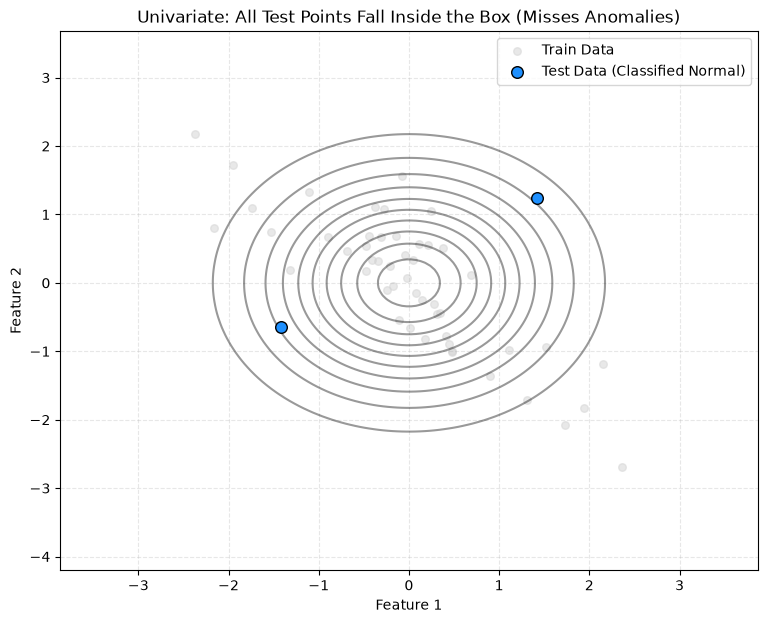

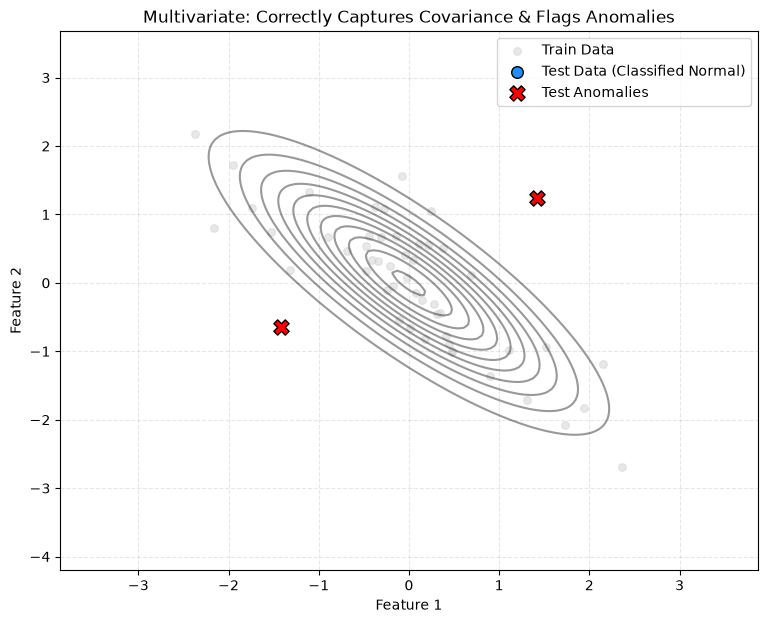

In [24]:
# Plotting function

def plot_test_points_emphasis(
    train_data,
    test_data,
    test_anomalies,
    mu,
    cov_or_sigma,
    model_type="univariate",
    title="Gaussian Anomaly Detection",
):
  plt.figure(figsize=(9, 7))

  # 1. Combine train and test data for proper scaling
  combined_data = np.vstack([train_data, test_data])
  x_min, x_max = combined_data[:, 0].min() - 1.5, combined_data[:, 0].max() + 1.5
  y_min, y_max = combined_data[:, 1].min() - 1.5, combined_data[:, 1].max() + 1.5

  x, y = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))

  # 2. Calculate probabilities (Z)
  if model_type == "univariate":
    sigma = cov_or_sigma
    z_x = norm.pdf(x, loc=mu[0], scale=sigma[0])
    z_y = norm.pdf(y, loc=mu[1], scale=sigma[1])
    z = z_x * z_y
  else:
    cov = cov_or_sigma
    grid = np.stack([x.ravel(), y.ravel()], axis=1)
    mv_normal = multivariate_normal(mean=mu, cov=cov, allow_singular=True)
    z = mv_normal.pdf(grid).reshape(x.shape)

  # Plot contours
  plt.contour(x, y, z, levels=12, colors="k", alpha=0.4)

  # 3. Plot Training Data (faded background)
  plt.scatter(
      train_data[:, 0],
      train_data[:, 1],
      c="lightgray",
      label="Train Data",
      alpha=0.5,
      s=30,
  )

  # 4. Plot Test Data with bold borders so they stand out clearly
  # Since univariate_anomalies_test is empty, all test points show up as normal (blue)
  plt.scatter(
      test_data[~test_anomalies, 0],
      test_data[~test_anomalies, 1],
      c="dodgerblue",
      edgecolors="k",
      label="Test Data (Classified Normal)",
      s=70,
      zorder=3,
  )

  if np.any(test_anomalies):
    plt.scatter(
        test_data[test_anomalies, 0],
        test_data[test_anomalies, 1],
        c="red",
        edgecolors="k",
        label="Test Anomalies",
        marker="X",
        s=120,
        zorder=4,
    )

  plt.xlim(x_min, x_max)
  plt.ylim(y_min, y_max)
  plt.title(title)
  plt.xlabel("Feature 1")
  plt.ylabel("Feature 2")
  plt.legend(loc="upper right")
  plt.grid(True, linestyle="--", alpha=0.3)
  plt.show()


# --- Run this for Univariate to see how it misses the test anomalies ---
plot_test_points_emphasis(
    train_data=ano_train_scaled,
    test_data=ano_test_scaled,
    test_anomalies=univariate_anomalies_test,
    mu=mu_u_train,
    cov_or_sigma=sigma_u_train,
    model_type="univariate",
    title="Univariate: All Test Points Fall Inside the Box (Misses Anomalies)",
)

# --- Run this for Multivariate to compare ---
plot_test_points_emphasis(
    train_data=ano_train_scaled,
    test_data=ano_test_scaled,
    test_anomalies=multivariate_anomalies_test,
    mu=mu_m_train,
    cov_or_sigma=cov_m_train,
    model_type="multivariate",
    title="Multivariate: Correctly Captures Covariance & Flags Anomalies",
)